# v1 – Sentimento com ML clássico

Classificação das avaliações da Olist em positivas/negativas com TF-IDF + regressão logística.

## Passo 1 – Carregar e explorar

Antes de treinar qualquer modelo, conhecer os dados: tamanho, colunas, como as notas se distribuem e quantas avaliações têm texto (só essas servem para um classificador de sentimento).

### 1. Imports e constantes

Caminho e nomes de colunas vêm de `delivery_ai.config`, e a limpeza vem de `delivery_ai.data` (código testado em `src/`). Assim notebook, testes e treino usam exatamente os mesmos valores.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from delivery_ai.config import (
    ID_COLUMN,
    MESSAGE_COLUMN,
    RANDOM_STATE,
    SCORE_COLUMN,
    SENTIMENT_COLUMN,
    SENTIMENT_NAMES,
)
from delivery_ai.data import (
    drop_duplicate_reviews,
    drop_neutral_reviews,
    keep_reviews_with_text,
    load_reviews,
    prepare_sentiment_dataset,
)

BAR_COLOR = "#2a78d6"

### 2. Carregar e ver o tamanho

In [2]:
reviews = load_reviews()

print(f"{reviews.shape[0]:,} linhas x {reviews.shape[1]} colunas")
reviews.head()

99,224 linhas x 7 colunas


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


### 3. Colunas e valores faltantes

O percentual de faltantes mostra quais informações dá para usar de verdade.

In [3]:
missing_percent = reviews.isna().mean().mul(100).round(1)

pd.DataFrame({"tipo": reviews.dtypes, "% faltante": missing_percent})

,tipo,% faltante
review_id,str,0.0
order_id,str,0.0
review_score,int64,0.0
review_comment_title,str,88.3
review_comment_message,str,58.7
review_creation_date,str,0.0
review_answer_timestamp,str,0.0


In [4]:
duplicated_ids = reviews[ID_COLUMN].duplicated().sum()

print(f"{ID_COLUMN} repetidos: {duplicated_ids}")

review_id repetidos: 814


### 4. Distribuição das notas

Mostra se as classes estão equilibradas. Se uma nota domina, um modelo que "chuta" sempre ela já acerta muito, e a acurácia sozinha engana.

In [5]:
def score_distribution(scores: pd.Series) -> pd.DataFrame:
    """Contagem e percentual de cada nota, de 1 a 5, para comparar grupos lado a lado."""
    counts = scores.value_counts().sort_index()
    return pd.DataFrame({"avaliações": counts, "%": (counts / counts.sum() * 100).round(1)})


all_scores = score_distribution(reviews[SCORE_COLUMN])
all_scores

,avaliações,%
review_score,,
1,11424,11.5
2,3151,3.2
3,8179,8.2
4,19142,19.3
5,57328,57.8


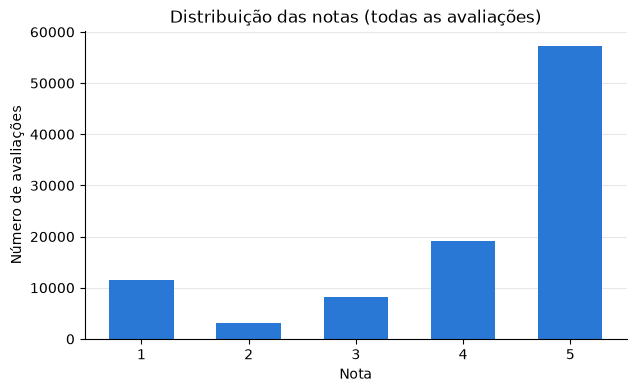

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(all_scores.index, all_scores["avaliações"], width=0.6, color=BAR_COLOR)
ax.set_title("Distribuição das notas (todas as avaliações)")
ax.set_xlabel("Nota")
ax.set_ylabel("Número de avaliações")
ax.set_xticks(all_scores.index)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 5. Quantas avaliações têm texto

Conta como comentário só a mensagem que não é vazia e não tem apenas espaços (regra de `keep_reviews_with_text`).

In [7]:
with_comment = keep_reviews_with_text(reviews)
comment_share = len(with_comment) / len(reviews)

print(f"Com comentário: {len(with_comment):,} ({comment_share:.1%})")
print(f"Sem comentário: {len(reviews) - len(with_comment):,} ({1 - comment_share:.1%})")

Com comentário: 40,950 (41.3%)
Sem comentário: 58,274 (58.7%)


### 6. Notas entre quem comentou

O modelo só vai ver avaliações com texto. Se clientes insatisfeitos comentam mais, o equilíbrio entre as notas muda em relação ao total.

In [8]:
pd.DataFrame(
    {
        "% todas": all_scores["%"],
        "% com comentário": score_distribution(with_comment[SCORE_COLUMN])["%"],
    }
)

,% todas,% com comentário
review_score,,
1,11.5,21.4
2,3.2,5.2
3,8.2,8.7
4,19.3,14.6
5,57.8,50.1


### 7. Conclusões

| O que vimos | Número | O que significa para a modelagem |
|---|---|---|
| Tamanho | 99.224 avaliações, 7 colunas | Volume suficiente para ML clássico. |
| Com comentário | 40.950 (41,3%) | ~59% das linhas não têm texto e saem do treino. O título (88% vazio) não compensa. |
| Nota 5 | 57,8% do total | Classes desbalanceadas: um modelo que sempre diz "positivo" já acerta muito. Por isso o baseline com `DummyClassifier` e métricas além da acurácia (F1, recall da classe negativa). |
| Notas 1–2 entre quem comentou | 26,6% (contra 14,7% no total) | Quem está insatisfeito comenta mais, então o conjunto com texto é menos desbalanceado que o total. |
| `review_id` repetidos | 814 | Precisam ser tratados na preparação para não contar a mesma avaliação duas vezes. |

**Próximo passo:** definir o rótulo (positivo/negativo) a partir da nota e decidir o que fazer com a nota 3.


## Passo 2 – Limpar e rotular

A limpeza fica em `src/delivery_ai/data.py`, coberta por testes; aqui ela só é aplicada e conferida.

Regras: manter só avaliações com texto, remover `review_id` repetido, descartar a nota 3 e rotular notas 1–2 como **negativo (0)** e 4–5 como **positivo (1)**.

### 1. Funil da limpeza

Quantas avaliações sobram a cada etapa: mostra onde perdemos dados e por quê.

In [9]:
without_duplicates = drop_duplicate_reviews(with_comment)
without_neutral = drop_neutral_reviews(without_duplicates)

funnel = pd.Series(
    {
        "Total": len(reviews),
        "Com texto": len(with_comment),
        "Sem duplicatas": len(without_duplicates),
        "Sem nota 3": len(without_neutral),
    },
    name="avaliações",
)
funnel.to_frame().assign(**{"% do total": (funnel / len(reviews) * 100).round(1)})

,avaliações,% do total
Total,99224,100.0
Com texto,40950,41.3
Sem duplicatas,40641,41.0
Sem nota 3,37113,37.4


### 2. Conjunto final e distribuição do sentimento

`prepare_sentiment_dataset` faz todas as etapas de uma vez; o `assert` confere que o resultado bate com o funil.

In [10]:
sentiment_dataset = prepare_sentiment_dataset(reviews)
assert len(sentiment_dataset) == funnel["Sem nota 3"]

sentiment_counts = sentiment_dataset[SENTIMENT_COLUMN].map(SENTIMENT_NAMES).value_counts()
pd.DataFrame(
    {
        "avaliações": sentiment_counts,
        "%": (sentiment_counts / sentiment_counts.sum() * 100).round(1),
    }
)

,avaliações,%
sentiment,,
positivo,26355,71.0
negativo,10758,29.0


### 3. Exemplos de cada classe

Ler alguns textos confere se o rótulo vindo da nota faz sentido.

In [11]:
EXAMPLES_PER_CLASS = 5

for label, name in SENTIMENT_NAMES.items():
    print(f"--- {name} ---")
    examples = sentiment_dataset[sentiment_dataset[SENTIMENT_COLUMN] == label].sample(
        EXAMPLES_PER_CLASS, random_state=RANDOM_STATE
    )
    for score, message in zip(examples[SCORE_COLUMN], examples[MESSAGE_COLUMN], strict=True):
        print(f"[nota {score}] {message}")
    print()

--- negativo ---
[nota 1] eu pedi o cancelamento na mesma hora e mesmo a assim mandaram para o correio só quero estorno o brigador 
[nota 1] Meu produto não foi entregue!! Quero meu dinheiro de volta!
[nota 1] Recebi a mercadoria e o produto não é ata funcionando!!! 
[nota 1] Não fiquei satisfeita; propaganda enganosa pois, disseram que era luminoso e na verdade NÃO É.E agora? Eu preciso que seja luminoso à noite lógico para aplicação de remédios tipo insulina,Vainia Lúcia
[nota 1] O produro não chegou. Não me deram nenbuma satisfação

--- positivo ---
[nota 5] O relógio é lindo e a entrega foi muito rápida, ele foi postado dia 24 e chegou dia 30, sendo que era frete comum e para o nordeste. Comprarei mais vezes!
[nota 5] Produto entregue antes do prazo. Muito bom.
[nota 5] recebi o produto intacto
[nota 5] O esperado. Obrigado!
[nota 5] Boneca original em perfeito estado.



### 4. Conclusões

- **37.113 avaliações** prontas para o modelo (37,4% do total): 26.355 positivas (71,0%) e 10.758 negativas (29,0%).
- O texto é o grande filtro: ~59% das avaliações não têm comentário. As duplicatas (309 linhas) e a nota 3 (3.528) pesam pouco.
- Continua desbalanceado (cerca de 7 positivas para cada 3 negativas). Um modelo que sempre diz "positivo" acertaria 71%, e esse é o número que o modelo de verdade precisa superar com folga.

**Por que descartar a nota 3?** Ela é ambígua: "chegou, mas atrasou" pode ser elogio ou reclamação. Forçá-la para um dos lados colocaria rótulos contraditórios no treino (ruído), e o modelo aprenderia uma fronteira confusa. Sem ela, o problema binário fica claro. A limitação é que, em produção, textos "mornos" ainda vão chegar, e o modelo vai empurrá-los para um dos lados.

**Próximo passo:** separar treino e teste e criar o baseline com `DummyClassifier`.
